# 模仿学习入门

本 notebook 在物理仿真器上从专家示范学习策略 $π_θ(a\mid s)$，体验训练与评估的基本流程，并理解常见实践。

模仿学习大致有两类方法：

- Behavioral Cloning（BC，行为克隆）：学习从输入观测到动作的映射。
- Inverse Reinforcement Learning（IRL，逆强化学习）：从示范中推断背后的奖励函数，再寻找能最大化该奖励的策略来复现期望行为。

本教材聚焦于生成模型兴起后快速发展的 BC。

本 notebook 将学习：

1. BC 的定义，以及简单回归策略的两个问题；
2. 在玩具任务中观察多峰性（同一观测对应多个正确动作）；
3. 在物理仿真器上训练和评估 BC 策略；
4. 使用深度生成模型 **Diffusion Policy**（扩散策略）挑战更难的任务。

**运行环境**：MuJoCo 的无头渲染需要 GPU。Colab 请选择 `运行时 → 更改运行时类型 → GPU`；本地环境默认使用 `pixi.toml`。


# 动机

Diffusion Policy：https://diffusion-policy.cs.columbia.edu/

ACT：https://arxiv.org/abs/2304.13705

pi0：https://www.pi.website/blog/pi0


# 注意

本资料是“在仿真环境中动手接触模仿学习的代码与带结果补充材料”，**不以课堂内逐单元执行为目标**。
尤其是数据集下载和训练部分会非常耗时；有时间的同学可以在自己的环境中运行，但不要只是无目的地反复点击按钮。Colab 免费额度还可能受到运行时长限制，需要拆分到多个 session 中，请提前规划。


## 环境准备

这里使用物理仿真器 [MuJoCo](https://mujoco.readthedocs.io/en/stable/overview.html)，使用为机器人学习封装 MuJoCo 并提供任务的 [robosuite](https://robosuite.ai/)，以及提供 robosuite 数据集和策略实现的 [robomimic](https://robomimic.github.io/)。

另一个框架是 [LeRobot](https://github.com/huggingface/lerobot)，其中实现了较新的模仿学习算法（ACT / Diffusion Policy）和 VLA（pi0 系列、smolvla 等），有 GPU 就可以方便地做实验。拥有或购买 SO101 等低成本机器人的同学，也可以进一步在真实机器人上实验。


In [ ]:
import sys, importlib.util
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB and importlib.util.find_spec("robomimic") is None:
    # Colab 既定的 numpy 2.x 保持执行（>=2 固定）．numpy 下的，重新起動不需要．
    # robomimic 是 PyPI 版个个古，DP / robosuite 1.5 支持是 master 仅因此 git 从入．
    !pip install -q "numpy>=2,<2.5" "mujoco<3.10" "robosuite>=1.5,<2" "imageio[ffmpeg]" h5py "robomimic @ git+https://github.com/ARISE-Initiative/robomimic.git"
    print("\n=== install done（重新起動无需 unzip・的下的cell方向進）===")
elif IN_COLAB:
    print("安装済 — 该続行执行．")
else:
    print("Colab 以外検出 — pixi 环境使想定，安装跳过．")

インストール済み — そのまま続行します．


In [ ]:
# MuJoCo 的无头描画配置（robosuite / mujoco 比前到必須）
import os
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["USE_FLAX"] = "0"
os.environ["USE_TF"] = "0"

import numpy as np
import torch
import torch.nn as nn
import h5py
import imageio
import matplotlib as mpl
import matplotlib.pyplot as plt

import robosuite
import robomimic
from diffusers import DDPMScheduler
print("robomimic", robomimic.__version__, "| robosuite", robosuite.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type != "cuda":
    print("⚠ GPU 未找到．Colab ，是『runtime → 更改 runtime 类型 → GPU』选择．")

SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED)

mpl.rcParams.update({
    "font.size": 8, "axes.labelsize": 9, "axes.titlesize": 10,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7,
    "axes.linewidth": 0.8, "figure.dpi": 110,
})
ACCENT = "#4C72B0"   # 动作分布，表方策（GMM / Diffusion）
GRAY   = "#B0B0B0"   # 动作1点，出次帰方策
RED    = "#C44E52"   # 潰予測的強調

[robosuite WARNING] No private macro file found! (macros.py:53)
[robosuite WARNING] It is recommended to use a private macro file (macros.py:54)
[robosuite WARNING] To setup, run: python /usr/local/lib/python3.12/dist-packages/robosuite/scripts/setup_macros.py (macros.py:55)
[robosuite WARNING] Could not import robosuite_models. Some robots may not be available. If you want to use these robots, please install robosuite_models from source (https://github.com/ARISE-Initiative/robosuite_models) or through pip install. (__init__.py:30)
[robosuite WARNING] Could not load the mink-based whole-body IK. Make sure you install related import properly, otherwise you will not be able to use the default IK controller setting for GR1 robot. (__init__.py:40)


robomimic 0.5.0 | robosuite 1.5.1
device: cuda


## Behavioral Cloning

在 BC 中，根据示范集合 $D=\{(s_i,a_i)\}$ 学习策略。不需要奖励或试错，可以把它看成一个“输入观测、输出动作”的**监督学习**问题。

<div align="center">

<table>
<tr><th></th><th>强化学习（RL）</th><th>模仿学习（IL）</th></tr>
<tr><td>学习信号</td><td>环境奖励</td><td>专家动作标签</td></tr>
<tr><td>探索</td><td>需要（试错）</td><td>不需要（模仿示范）</td></tr>
<tr><td>弱点</td><td>奖励稀疏时困难</td><td>面对示范未覆盖的状态时脆弱</td></tr>
</table>

</div>

最朴素的策略是把观测映射到**一个动作点**的函数 $\pi_\theta(s)$，并用二次误差回归：

$$\theta^* = \arg\min_\theta\;\mathbb{E}_{(s,a)\sim D}\big[\,\lVert\pi_\theta(s)-a\rVert^2\,\big].$$

在 robomimic 中，这个算法名为 `bc`（内部是 CNN+MLP 回归）。它很简单，但“输出一个动作点”“每次只输出一步”会带来两个问题。

**问题 1：同一观测存在多个正确答案时。** 二次误差会把多个答案平均起来，输出一个不属于任何正确模式的动作。

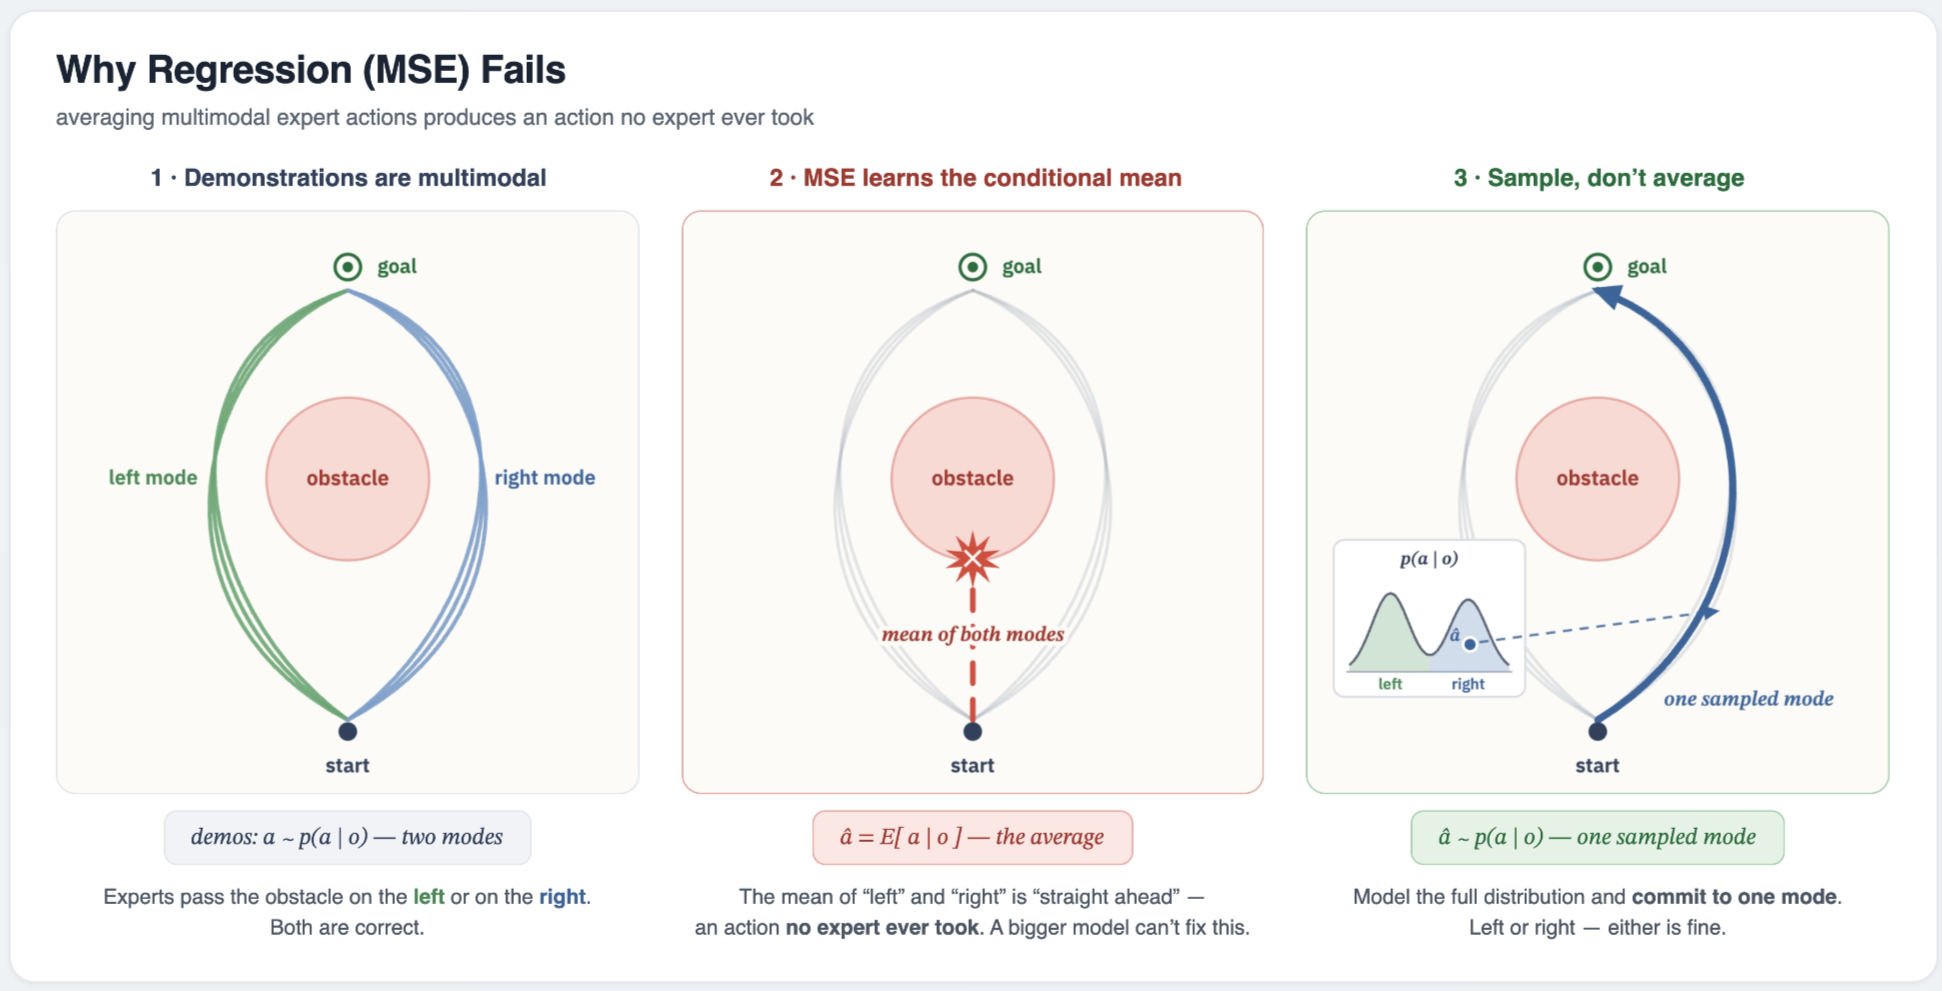

**问题 2：误差沿时间累积（compounding error）。** 每次只输出一步时，细小偏差会改变下一次观测，策略逐步进入示范没有覆盖的状态，形成 OOD（共变量偏移，covariate shift）。任务越长，这个问题越明显。

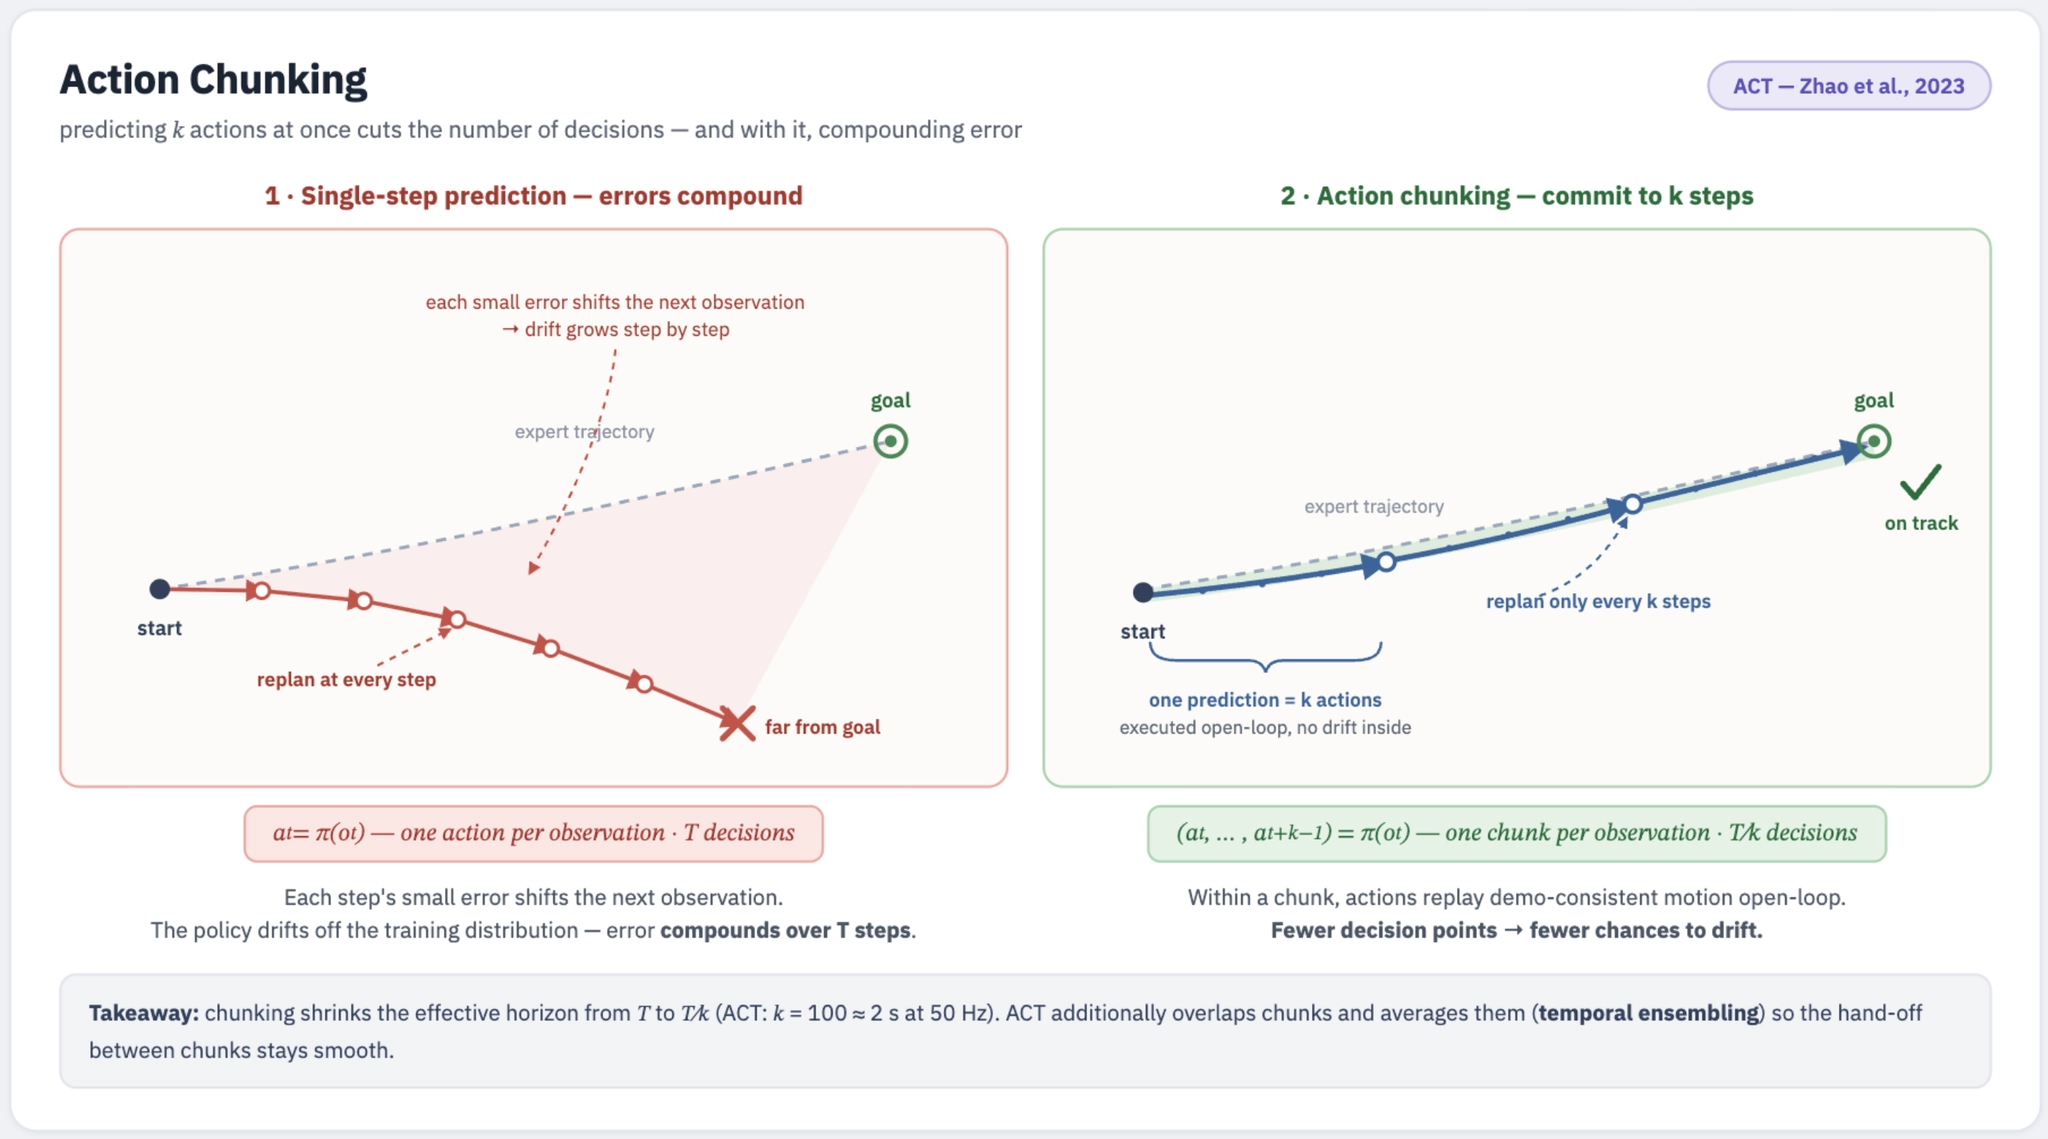

后面介绍的 **Diffusion Policy** 会把策略从回归模型换成**生成模型**，并且一次输出一段动作而不是一个时间步。它仍然是同一种模仿学习（BC），改变的只是策略表示。接下来将依次观察它如何缓解这两个问题。


## 在玩具任务中观察简单回归的局限

先用最小配置观察问题 1（同一观测对应多个正确动作）。对于状态 $s\in[-1,1]$，专家会凭“心情”以相同概率选择**上方路径 $a=+1$**或**下方路径 $a=-1$**，而 $s$ 不决定选择哪条路径。

此时二次误差的最优答案是两个动作的平均值 $\tfrac{(+1)+(-1)}{2}=0$。这个动作从未出现在示范中，等价于朝墙走。下面用真实生成的数据比较三种策略表示：

- **回归（MSE）**：返回一个动作点；
- **GMM（高斯混合模型）**：用混合高斯 $p(a\mid s)=\sum_k \pi_k N(\mu_k,\sigma_k)$ 表示动作分布。**分布峰值数量 $M$ 必须预先指定**；太少会把多个峰压在一起，太多则多余成分的权重会降到 0。本玩具任务使用真实峰数 $M=2$；
- **Diffusion Model（扩散模型）**：从噪声中去噪并**采样**动作，是 Diffusion Policy 的最小版本。


In [ ]:
# 相同 s 到 a=+1 与 a=-1 混在执行多峰示范
N = 2000
s = torch.rand(N, 1) * 2 - 1
mode = (torch.rand(N, 1) < 0.5).float()
a = torch.where(mode.bool(), torch.ones_like(s), -torch.ones_like(s)) + 0.08 * torch.randn(N, 1)

def trunk():
    return nn.Sequential(nn.Linear(1, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU())

# 次帰方策（动作1点返次）
reg = nn.Sequential(trunk(), nn.Linear(64, 1))
opt = torch.optim.Adam(reg.parameters(), lr=1e-2)
for _ in range(1500):
    loss = ((reg(s) - a) ** 2).mean()
    opt.zero_grad(); loss.backward(); opt.step()
print(f"次帰的最終 loss = {loss.item():.3f}  (分散 ≈ 1 = 平均0到潰証拠)")

回帰の最終 loss = 0.996  (分散 ≈ 1 = 平均0に潰れた証拠)


In [ ]:
# GMM 方策（动作混合高斯，表）
M = 2
class MDN(nn.Module):
    def __init__(self):
        super().__init__()
        self.t = trunk(); self.pi = nn.Linear(64, M); self.mu = nn.Linear(64, M); self.log_sigma = nn.Linear(64, M)
    def forward(self, x):
        h = self.t(x)
        return self.pi(h), self.mu(h), self.log_sigma(h).clamp(-7, 2)

mdn = MDN(); opt = torch.optim.Adam(mdn.parameters(), lr=1e-2)
for _ in range(3000):
    pi, mu, ls = mdn(s)
    log_comp = (-0.5 * ((a - mu) / ls.exp()) ** 2 - ls - 0.9189) + torch.log_softmax(pi, -1)
    loss = -torch.logsumexp(log_comp, -1).mean()      # 混合高斯的負対几尤度
    opt.zero_grad(); loss.backward(); opt.step()

# 拡散模型（动作噪声从生成）
sched = DDPMScheduler(num_train_timesteps=100, beta_schedule="squaredcos_cap_v2", clip_sample=True)
class DiffusionHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(1 + 1 + 16, 128), nn.SiLU(), nn.Linear(128, 128), nn.SiLU(), nn.Linear(128, 1))
    def t_embed(self, t):
        f = 10000 ** (-torch.arange(8) / 8); x = t[:, None].float() * f[None]
        return torch.cat([x.sin(), x.cos()], -1)
    def forward(self, noisy_a, t, cond):                # 噪声予測
        return self.net(torch.cat([noisy_a, cond, self.t_embed(t)], -1))

dh = DiffusionHead(); opt = torch.optim.Adam(dh.parameters(), lr=1e-3)
for _ in range(4000):
    i = torch.randint(0, N, (256,)); a0, cond = a[i], s[i]
    t = torch.randint(0, 100, (256,)); noise = torch.randn_like(a0)
    noisy = sched.add_noise(a0, noise, t)
    loss = ((dh(noisy, t, cond) - noise) ** 2).mean()   # 噪声予測的 MSE
    opt.zero_grad(); loss.backward(); opt.step()

@torch.no_grad()
def diffusion_sample(cond):
    x = torch.randn(cond.shape[0], 1); sched.set_timesteps(100)
    for t in sched.timesteps:
        x = sched.step(dh(x, torch.full((cond.shape[0],), t), cond), t, x).prev_sample
    return x
print("3 方策训练完成")

3 方策学習完了


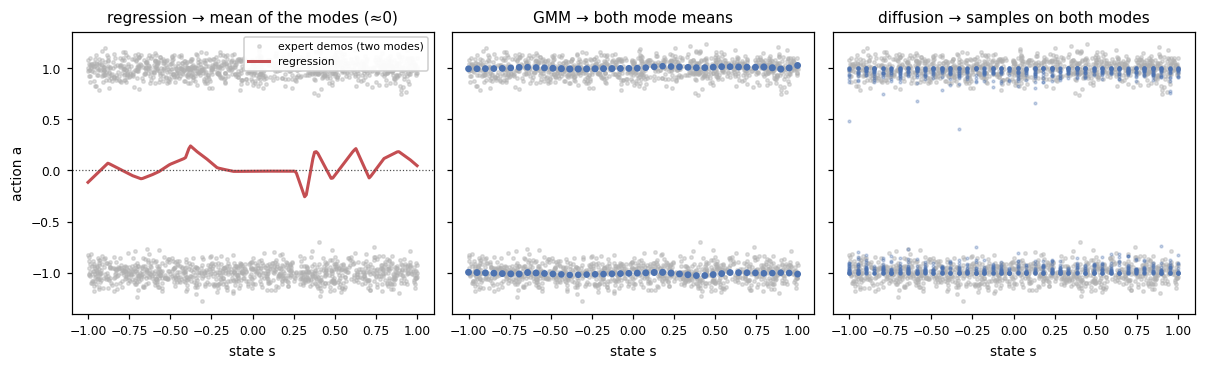

In [ ]:
# p(a|s)  3 方策，可視化
grid = torch.linspace(-1, 1, 200).unsqueeze(1)
cgrid = torch.linspace(-1, 1, 40).unsqueeze(1)
with torch.no_grad():
    reg_pred = reg(grid)
    pi, mu, ls = mdn(cgrid); pic = torch.softmax(pi, -1)
    dif = diffusion_sample(cgrid.repeat_interleave(40, 0))

fig, ax = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for x in ax:
    x.scatter(s, a, s=5, c=GRAY, alpha=0.4, label="expert demos (two modes)")
    x.set_xlabel("state s")
ax[0].plot(grid, reg_pred, c=RED, lw=2, label="regression")
ax[0].axhline(0, c="0.3", lw=0.8, ls=":"); ax[0].set_title("regression → mean of the modes (≈0)")
for k in range(M):
    ax[1].scatter(cgrid, mu[:, k], s=20 * pic[:, k] + 2, c=ACCENT)
ax[1].set_title("GMM → both mode means")
ax[2].scatter(cgrid.repeat_interleave(40, 0), dif, s=3, c=ACCENT, alpha=0.3)
ax[2].set_title("diffusion → samples on both modes")
ax[0].set_ylabel("action a"); ax[0].legend(loc="upper right", framealpha=0.95)
fig.tight_layout(); plt.show()

从左图的回归结果（红色）可以看到，它会贴在两个 mode 中间的 $≈0$。当同一观测有两种动作时，这个策略会输出示范中不存在的平均动作。

相反，把动作表示成**分布**的策略（GMM、扩散模型）可以保留 $+1$ 和 $-1$ 两个峰。相同的示范和目标，只改变策略表示，结果就会不同。不过 GMM 必须预先给出峰数 $M$，扩散模型则不需要这个设定，可以表示任意形状的分布。现实世界的图像、视频等数据通常是高维的，mode 数量也未知。

当然，这个现象的根源是观测 $s$ 不决定动作。后面的 lift / square 会以图像和精确状态作为条件，观测几乎唯一决定动作，因此多峰性不明显。真实机器人更突出的往往是问题 2（误差累积）；Diffusion Policy 通过一次生成一段动作序列来缓解它。


## 准备用于 BC 的机器人数据

[robomimic](https://robomimic.github.io/) 提供 robosuite 上的**机器人操作示范集**和训练算法。本次使用 **ph（proficient human，熟练人工遥操作）**的两个任务：

- **Lift**：抓住红色方块并抬起。任务短、解法几乎唯一；
- **Square**：把方形螺母插入固定插销（nut-assembly）。任务更长，接触过程更精细。

“短且容易 / 长且困难”的对比，会影响问题 2（误差累积）的严重程度。

robosuite 1.5 系列的数据文件 `demo_v15.hdf5` 只有状态序列和动作序列，没有观测图像。这里把状态序列在仿真器中重放，再用相机渲染，生成带图像的 `image_v15.hdf5`。


In [ ]:
import os, sys, subprocess

DATA_DIR     = "datasets"
DATASET_TYPE = "ph"
N_DEMOS      = None   # 画像化执行示范几．None=全部部200个．50 等设为后高速（性能是落）

# 输入到使观测-（画像2枚 + 末端的自己受容感覚．物体的真值 object 是使）
RGB_KEYS = ["agentview_image", "robot0_eye_in_hand_image"]
LOW_KEYS = ["robot0_eef_pos", "robot0_eef_quat", "robot0_gripper_qpos"]
ALL_OBS  = sorted(RGB_KEYS + LOW_KEYS)

def sh(cmd):
    print("$", " ".join(cmd)); sys.stdout.flush(); subprocess.run(cmd, check=True)

# 生几据DL → 状態重新生并84x84画像付与 → image_v15.hdf5 的路径返次
def prepare_dataset(task):
    raw = os.path.join(DATA_DIR, task, DATASET_TYPE, "demo_v15.hdf5")
    img = os.path.join(DATA_DIR, task, DATASET_TYPE, "image_v15.hdf5")
    if not os.path.exists(raw):
        sh([sys.executable, "-m", "robomimic.scripts.download_datasets",
            "--tasks", task, "--dataset_types", DATASET_TYPE,
            "--hdf5_types", "raw", "--download_dir", DATA_DIR])
    if not os.path.exists(img):
        cmd = [sys.executable, "-m", "robomimic.scripts.dataset_states_to_obs",
               "--done_mode", "2", "--dataset", raw, "--output_name", "image_v15.hdf5",
               "--camera_names", "agentview", "robot0_eye_in_hand",
               "--camera_height", "84", "--camera_width", "84"]
        if N_DEMOS is not None: cmd += ["--n", str(N_DEMOS)]
        sh(cmd)
    return img

In [ ]:
# 両任务的几据準備（几分．Square 是轨迹较长部分小时还是还是）
LIFT_DATA   = prepare_dataset("lift")
SQUARE_DATA = prepare_dataset("square")
print("\nlift  :", LIFT_DATA)
print("square:", SQUARE_DATA)


lift  : datasets/lift/ph/image_v15.hdf5
square: datasets/square/ph/image_v15.hdf5


In [ ]:
# 每个1示范视频，眺
from IPython.display import Video, display
def demo_video(path, out, demo="demo_0"):
    with h5py.File(path, "r") as f:
        frames = f["data"][demo]["obs"]["agentview_image"][:]
    w = imageio.get_writer(out, fps=20)
    for fr in frames: w.append_data(fr)
    w.close(); return out

demo_video(LIFT_DATA,   "demo_lift.mp4")
demo_video(SQUARE_DATA, "demo_square.mp4")
print("Lift demo:");   display(Video("demo_lift.mp4", embed=True, width=300))
print("Square demo:"); display(Video("demo_square.mp4", embed=True, width=300))

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (84, 84) to (96, 96) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).
IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (84, 84) to (96, 96) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Lift demo:


Square demo:


## 查看数据集分布

开始训练前，先观察数据如何分布。不了解初始状态范围和动作内容就直接训练模仿策略很危险，因为**策略是否成功、任务有多难，都高度依赖数据分布**。这里从三个角度可视化 Lift 和 Square 的 robomimic 数据集：

- **初始状态叠加**：叠加各示范的初始帧，观察物体从哪里开始；
- **动作分布**：绘制每个动作维度的直方图，查看取值范围、饱和和夹爪二值性；
- **末端 3D 轨迹**：在三维空间叠加所有示范的末端位置，观察运动的范围与复杂度。



============= Initialized Observation Utils with Obs Spec =============

using obs modality: rgb with keys: ['agentview_image']
using obs modality: low_dim with keys: []
Created environment with name Lift
Action size is 7
Created environment with name NutAssemblySquare
Action size is 7


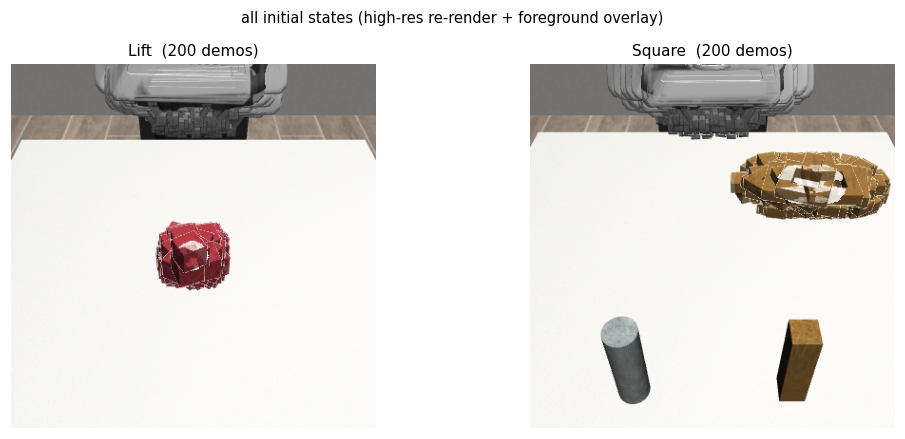

In [ ]:
# 綺麗画像出为了到重新rendering并，还是小时还是还是
# 训练仅完成場合skip并OK
import robomimic.utils.file_utils as FileUtils
import robomimic.utils.env_utils as EnvUtils
import robomimic.utils.obs_utils as ObsUtils
ObsUtils.initialize_obs_utils_with_obs_specs({"obs": {"rgb": ["agentview_image"], "low_dim": []}})

def initial_state_overlay(dataset_path, px=384, scale=25.0, amax=0.85):
    em  = FileUtils.get_env_metadata_from_dataset(dataset_path=dataset_path)
    env = EnvUtils.create_env_from_metadata(env_meta=em, render=False, render_offscreen=True, use_image_obs=True)
    frames = []
    with h5py.File(dataset_path, "r") as f:
        for d in f["data"]:
            env.reset_to({"states": f["data"][d]["states"][0], "model": f["data"][d].attrs["model_file"]})
            frames.append(env.render(mode="rgb_array", height=px, width=px, camera_name="agentview").astype(np.float32))
    ff = np.stack(frames)
    bg = np.median(ff, 0); comp = bg.copy()             # median = 動还是背景
    for fr in ff:
        alpha = np.clip(np.abs(fr - bg).mean(-1) / scale, 0, amax)[..., None]   # 前景程度不透明
        comp = (1 - alpha) * comp + alpha * fr
    return comp.clip(0, 255).astype(np.uint8), ff.shape[0]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (task, path) in zip(ax, [("Lift", LIFT_DATA), ("Square", SQUARE_DATA)]):
    img, n = initial_state_overlay(path)
    a.imshow(img); a.set_title(f"{task}  ({n} demos)"); a.axis("off")
fig.suptitle("all initial states (high-res re-render + foreground overlay)")
fig.tight_layout(); plt.show()

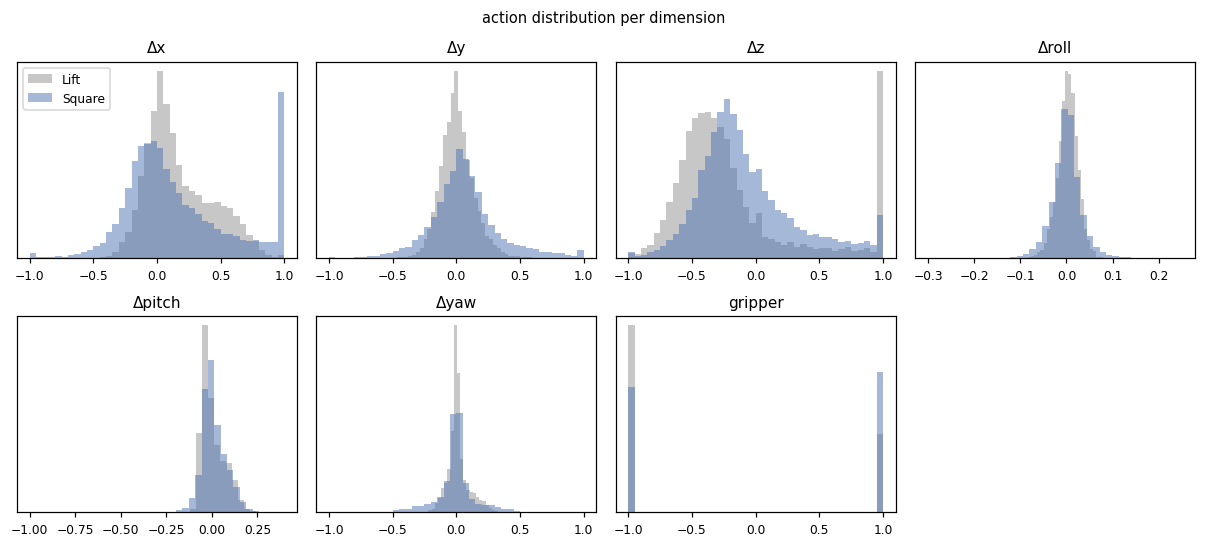

In [ ]:
# 动作的分布：7 维度每个的直方图（Lift vs Square）
def all_actions(path):
    with h5py.File(path, "r") as f:
        return np.concatenate([f["data"][d]["actions"][:] for d in f["data"]])

la, sa = all_actions(LIFT_DATA), all_actions(SQUARE_DATA)
names = ["Δx", "Δy", "Δz", "Δroll", "Δpitch", "Δyaw", "gripper"]
fig, ax = plt.subplots(2, 4, figsize=(11, 5))
for j in range(7):
    a = ax.flat[j]
    a.hist(la[:, j], bins=40, density=True, color=GRAY,   alpha=0.7, label="Lift")
    a.hist(sa[:, j], bins=40, density=True, color=ACCENT, alpha=0.5, label="Square")
    a.set_title(names[j]); a.set_yticks([])
ax.flat[7].axis("off"); ax.flat[0].legend(fontsize=8)
fig.suptitle("action distribution per dimension"); fig.tight_layout(); plt.show()

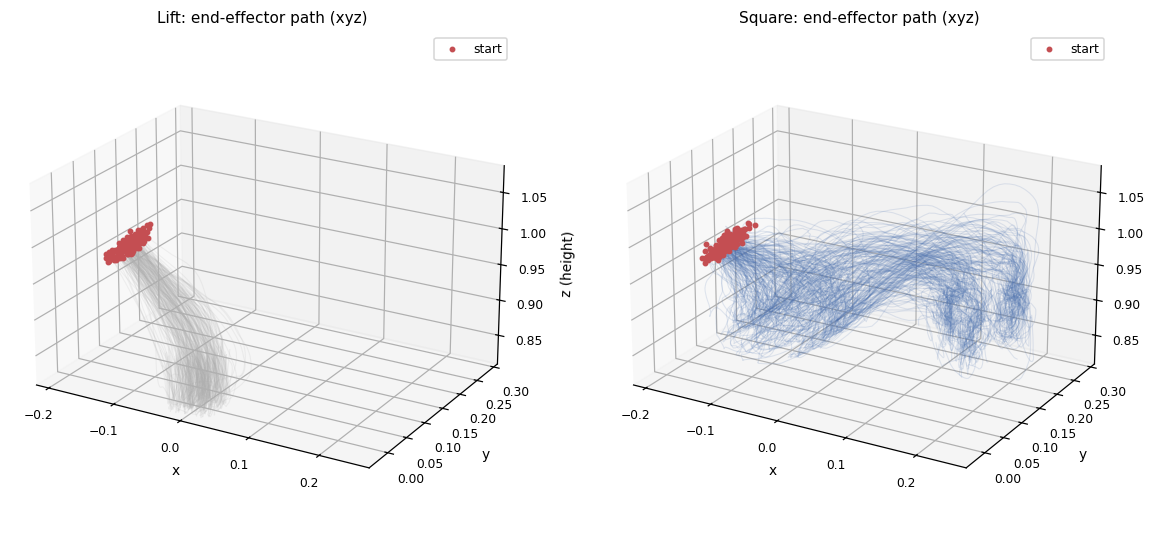

In [ ]:
# 末端的軌跡（3D）：全部部示范的末端 xyz 重，Lift 与 Square 相同軸範囲・等比，比較执行
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (projection="3d" 启用)

def eef_list(path):
    with h5py.File(path, "r") as f:
        return [f["data"][d]["obs"]["robot0_eef_pos"][:] for d in f["data"]]

lift_e, sq_e = eef_list(LIFT_DATA), eef_list(SQUARE_DATA)
allp = np.concatenate(lift_e + sq_e)
lims = [(allp[:, j].min(), allp[:, j].max()) for j in range(3)]   # 両任务共通的軸範囲
rng  = [hi - lo for lo, hi in lims]

fig = plt.figure(figsize=(11, 5))
for i, (task, eefs, c) in enumerate([("Lift", lift_e, GRAY), ("Square", sq_e, ACCENT)]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    for e in eefs:
        ax.plot(e[:, 0], e[:, 1], e[:, 2], c=c, alpha=0.15, lw=0.7)
    ax.scatter([e[0, 0] for e in eefs], [e[0, 1] for e in eefs], [e[0, 2] for e in eefs],
               s=8, c=RED, depthshade=False, label="start")
    ax.set_xlim(lims[0]); ax.set_ylim(lims[1]); ax.set_zlim(lims[2])
    ax.set_box_aspect(rng)                       # 共通範囲＋等比 → 相同尺度，比較
    ax.set_title(f"{task}: end-effector path (xyz)")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z (height)")
    ax.view_init(elev=22, azim=-60); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

解读：

- **Lift** 的单个 episode 很短（平均约 50 步），轨迹简单，因此朴素回归也容易学习。
- **Square** 的轨迹复杂，抓取和插入阶段会分叉，episode 也更长（平均约 150 步）。轨迹越长，误差越容易累积，对回归策略越苛刻。
- 动作分布中，夹爪维度会分成约 ±1 的二值两类，平移维度两端还可能出现饱和尖峰。了解这些特征，有助于定位训练失败的原因。


## 训练与评估辅助函数

使用 robomimic 经过验证的组件构建、训练和评估策略，同时只把训练循环本身展开，方便理解：

- `build_model`：通过 `config_factory` + `algo_factory` 创建模型（`bc` 和 `diffusion_policy` 使用同一个入口）；
- `make_loader`：从 `SequenceDataset` 提供 batch；
- `train`：一个梯度步骤 = `process_batch → train_on_batch`；
- `make_eval_env` / `rollout` / `evaluate`：让策略在仿真环境中运行，测量成功率并保存视频。


In [ ]:
import robomimic.utils.obs_utils as ObsUtils
import robomimic.utils.file_utils as FileUtils
from robomimic.config import config_factory
from robomimic.algo import algo_factory
from robomimic.utils.dataset import SequenceDataset
from torch.utils.data import DataLoader

# 训练規模（GPU 前提，控．几值正确与出中只有増和）
BATCH_SIZE      = 16
STEPS_PER_EPOCH = 100
NUM_EPOCHS      = {"bc": 100, "diffusion_policy": 200}   # 次帰是収束速 / 拡散是很大的，多

def build_model(algo, dataset_path):
    config = config_factory(algo_name=algo)
    with config.values_unlocked():
        config.train.data = [{"path": dataset_path}]
        config.train.batch_size = BATCH_SIZE
        config.observation.modalities.obs.low_dim = LOW_KEYS
        config.observation.modalities.obs.rgb = RGB_KEYS
        if algo == "diffusion_policy":
            # cosine LR scheduler到総步几渡（train.py 与相同注意意入）
            config.train.num_epochs = NUM_EPOCHS[algo]
            config.algo.optim_params.policy["num_train_batches"] = STEPS_PER_EPOCH
            config.algo.optim_params.policy["num_epochs"] = NUM_EPOCHS[algo]
    ObsUtils.initialize_obs_utils_with_config(config)
    sm = FileUtils.get_shape_metadata_from_dataset(
        dataset_config=config.train.data[0],
        action_keys=config.train.action_keys, all_obs_keys=ALL_OBS)
    model = algo_factory(algo, config,
        obs_key_shapes=sm["all_shapes"], ac_dim=sm["ac_dim"], device=device)
    return model, config

ROBOMIMIC WARNING(
    No private macro file found!
    It is recommended to use a private macro file
    To setup, run: python /home/tatsuya.kamijo/imitation_learning/.pixi/envs/default/lib/python3.10/site-packages/robomimic/scripts/setup_macros.py
)


In [ ]:
def make_loader(dataset_path, config):
    ds = SequenceDataset(
        hdf5_path=dataset_path, obs_keys=ALL_OBS, action_keys=("actions",),
        dataset_keys=("actions", "rewards", "dones"), action_config={"actions": {}},
        load_next_obs=False,
        frame_stack=config.train.frame_stack, seq_length=config.train.seq_length,
        pad_frame_stack=True, pad_seq_length=True, get_pad_mask=False, goal_mode=None,
        hdf5_cache_mode="low_dim",   # 低维度是内存，图像是磁盘（省内存）
        hdf5_use_swmr=True, hdf5_normalize_obs=False, filter_by_attribute=None)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True)

def train(model, data_loader, num_epochs, tag):
    model.set_train(); loss_hist, it = [], iter(data_loader)
    for epoch in range(1, num_epochs + 1):
        ep = []
        for _ in range(STEPS_PER_EPOCH):
            try: batch = next(it)
            except StopIteration: it = iter(data_loader); batch = next(it)
            inp = model.process_batch_for_training(batch)
            inp = model.postprocess_batch_for_training(inp, obs_normalization_stats=None)
            info = model.train_on_batch(batch=inp, epoch=epoch, validate=False)  # 1勾配step
            model.on_gradient_step()   # per-batch 的 LR scheduler進（拡散的 cosine+warmup 到必須）
            ep.append(model.log_info(info)["Loss"])
        model.on_epoch_end(epoch); loss_hist.append(float(np.mean(ep)))
        if epoch % 25 == 0 or epoch == 1:
            print(f"[{tag}] epoch {epoch:4d}/{num_epochs}  loss = {loss_hist[-1]:.4f}")
    return loss_hist

In [ ]:
import robomimic.utils.env_utils as EnvUtils
from robomimic.algo import RolloutPolicy
from robomimic.envs.env_base import EnvBase
from robomimic.envs.wrappers import EnvWrapper, FrameStackWrapper

def make_eval_env(dataset_path):
    em = FileUtils.get_env_metadata_from_dataset(dataset_path=dataset_path)
    return EnvUtils.create_env_from_metadata(env_meta=em, render=False,
        render_offscreen=True, use_image_obs=True)

# 1episode転并成功完成还是返次
def rollout(policy, env, horizon, video_writer=None, video_skip=5, camera_names=("agentview",)):
    assert isinstance(env, (EnvBase, EnvWrapper)) and isinstance(policy, RolloutPolicy)
    policy.start_episode()
    obs = env.reset(); obs = env.reset_to(env.get_state())   # robosuite 的状態与观测一致
    success, vc = False, 0
    try:
        for step_i in range(horizon):
            obs, r, done, _ = env.step(policy(ob=obs))
            success = bool(env.is_success()["task"])
            if video_writer is not None and vc % video_skip == 0:
                frames = [env.render(mode="rgb_array", height=256, width=256, camera_name=c) for c in camera_names]
                video_writer.append_data(np.concatenate(frames, axis=1))
            vc += 1
            if done or success: break
    except env.rollout_exceptions as e:
        print("rollout exception:", e)
    return float(success)

def evaluate(model, base_env, config, n_rollouts, horizon, video_path, n_video=3):
    fs = config.train.frame_stack   # 拡散是观测 frame_stack 枚積，渡
    env = FrameStackWrapper(base_env, num_frames=fs) if fs > 1 else base_env
    policy = RolloutPolicy(model)
    writer = imageio.get_writer(video_path, fps=20); succ = []
    for i in range(n_rollouts):
        succ.append(rollout(policy, env, horizon, video_writer=(writer if i < n_video else None)))
    writer.close()
    rate = float(np.mean(succ))
    print(f"==> 成功率: {rate*100:.1f}%  ({int(sum(succ))}/{n_rollouts})")
    return rate

In [ ]:
# 评估配置
N_ROLLOUTS = 20
HORIZON    = {"lift": 300, "square": 400}   # Square 是较长
SUCCESS    = {}                              # (task, algo) -> 成功率

## 用回归策略训练 Lift 任务

Lift 很短，解法几乎唯一；观测基本决定动作，轨迹也短，所以多峰性和误差累积都不明显。使用朴素回归策略（robomimic 的 `bc`）应该足够。


In [ ]:
reg_lift, cfg = build_model("bc", LIFT_DATA)
lift_reg_loss = train(reg_lift, make_loader(LIFT_DATA, cfg), NUM_EPOCHS["bc"], "regress/lift")
lift_env = make_eval_env(LIFT_DATA)
np.random.seed(SEED); torch.manual_seed(SEED)
SUCCESS[("lift", "bc")] = evaluate(reg_lift, lift_env, cfg, N_ROLLOUTS, HORIZON["lift"], "reg_lift.mp4")


============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_eef_pos', 'robot0_gripper_qpos', 'robot0_eef_quat']
using obs modality: rgb with keys: ['robot0_eye_in_hand_image', 'agentview_image']
using obs modality: depth with keys: []
using obs modality: scan with keys: []
SequenceDataset: loading dataset into memory...
100%|██████████████████████████████████████████████████| 200/200 [00:00<00:00, 944.14it/s]
SequenceDataset: computing action statistics...
100%|█████████████████████████████████████████████████| 199/199 [00:00<00:00, 5074.21it/s]
[regress/lift] epoch    1/100  loss = 0.0558
[regress/lift] epoch   25/100  loss = 0.0180
[regress/lift] epoch   50/100  loss = 0.0154
[regress/lift] epoch   75/100  loss = 0.0164
[regress/lift] epoch  100/100  loss = 0.0100
Created environment with name Lift
Action size is 7
ObservationKeyToModalityDict: object not found, adding object to mapping with assumed low_dim modality!
Obser

In [ ]:
from IPython.display import Video
Video("reg_lift.mp4", embed=True, width=320)

在 Lift 中，回归策略可以取得较高成功率。对于观测基本决定动作、轨迹又短的任务，用一个动作点表示的朴素策略就够了。接下来在轨迹更长、接触更精细的 Square 上试试同一个策略。


## 用回归策略训练 Square 任务

Square 要把方形螺母插入固定插销，轨迹长且接触精细。这里沿用相同的回归策略并观察成功率。


In [ ]:
reg_square, cfg = build_model("bc", SQUARE_DATA)
square_reg_loss = train(reg_square, make_loader(SQUARE_DATA, cfg), NUM_EPOCHS["bc"], "regress/square")
square_env = make_eval_env(SQUARE_DATA)
np.random.seed(SEED); torch.manual_seed(SEED)
SUCCESS[("square", "bc")] = evaluate(reg_square, square_env, cfg, N_ROLLOUTS, HORIZON["square"], "reg_square.mp4")


============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_eef_pos', 'robot0_gripper_qpos', 'robot0_eef_quat']
using obs modality: rgb with keys: ['robot0_eye_in_hand_image', 'agentview_image']
using obs modality: depth with keys: []
using obs modality: scan with keys: []
SequenceDataset: loading dataset into memory...
100%|██████████████████████████████████████████████████| 200/200 [00:00<00:00, 935.22it/s]
SequenceDataset: computing action statistics...
100%|█████████████████████████████████████████████████| 199/199 [00:00<00:00, 4692.56it/s]
[regress/square] epoch    1/100  loss = 0.0915
[regress/square] epoch   25/100  loss = 0.0341
[regress/square] epoch   50/100  loss = 0.0276
[regress/square] epoch   75/100  loss = 0.0268
[regress/square] epoch  100/100  loss = 0.0242
Created environment with name NutAssemblySquare
Action size is 7
ObservationKeyToModalityDict: object not found, adding object to mapping with assumed 

In [ ]:
Video("reg_square.mp4", embed=True, width=320)

Square 的成功率明显下降。视频中可能会看到策略在插销前犹豫，或者停在不完整的位置。这里混合了两个因素：

一是训练量。本 notebook 受 GPU 和时间限制，训练规模较小；训练充分后，回归策略也可能更好地解决 square-ph，因此不能简单概括为“回归无法解决 Square”。

二是长轨迹上的误差累积（compounding error）。每一步很小的偏差会改变下一次观测，使策略逐渐流向示范中没有的状态。这是逐步输出动作这一方案的结构性弱点，即使增加训练量也可能残留。接下来使用能缓解该问题的 Diffusion Policy，在相同 Square 和相同训练循环下继续实验。


# 扩散模型

在去噪 score matching 中，网络学习预测目标分布 $p(x)$ 的 score function（得分函数）$\nabla_x \log p(x)$，也就是对数似然关于输入的梯度，从而建模真实分布。

这与预测加入数据的噪声只差一个常数比例（证明略）。

## 为什么学习 score 而不是直接学习密度

如果直接建模分布 $p(x)$，通常需要归一化常数，例如 $p_\theta(x)=e^{-f_\theta(x)}/Z_\theta$，其中 $Z_\theta=\int e^{-f_\theta(x)}\,dx$。高维积分难以计算，训练也因此困难。

score 是对数密度关于输入 $x$ 的梯度：

$$\nabla_x \log p_\theta(x)=-\nabla_x f_\theta(x)-\underbrace{\nabla_x \log Z_\theta}_{=0}$$

归一化常数不依赖 $x$，微分后会消失。因此学习 score 时完全不必计算难处理的 $Z_\theta$，仍能捕捉分布形状。

## 知道 score 有什么用

在每个点上，score 指向对数密度增加、概率更高的方向，是一个向量场。知道它后，无需计算密度值本身，也能从分布中采样。代表性方法是 Langevin dynamics：

$$x_{k+1}=x_k+\frac{\delta}{2}\nabla_x\log p(x_k)+\sqrt{\delta}\,z,\quad z\sim N(0,I)$$

score 把样本推向高密度区域，噪声则把样本扩散到整个分布。二者平衡后，经过足够多步，$x_k$ 就会成为来自 $p(x)$ 的样本。

## 作为扩散模型的形式化

单独准确估计一个分布的 score 并不容易，尤其在数据稀疏的低密度区域。因此扩散模型逐步向数据加噪，考虑每个噪声等级 $t$ 的分布 $p_t(x)$，并在各个等级学习 score $s_\theta(x_t,t)$。

生成时从纯噪声（$t=T$）开始，按照学到的 score 一点点去噪，直到 $t=0$。逆过程的每一步都类似 Langevin dynamics；二者都可以看作同一个反向 SDE 的离散化。





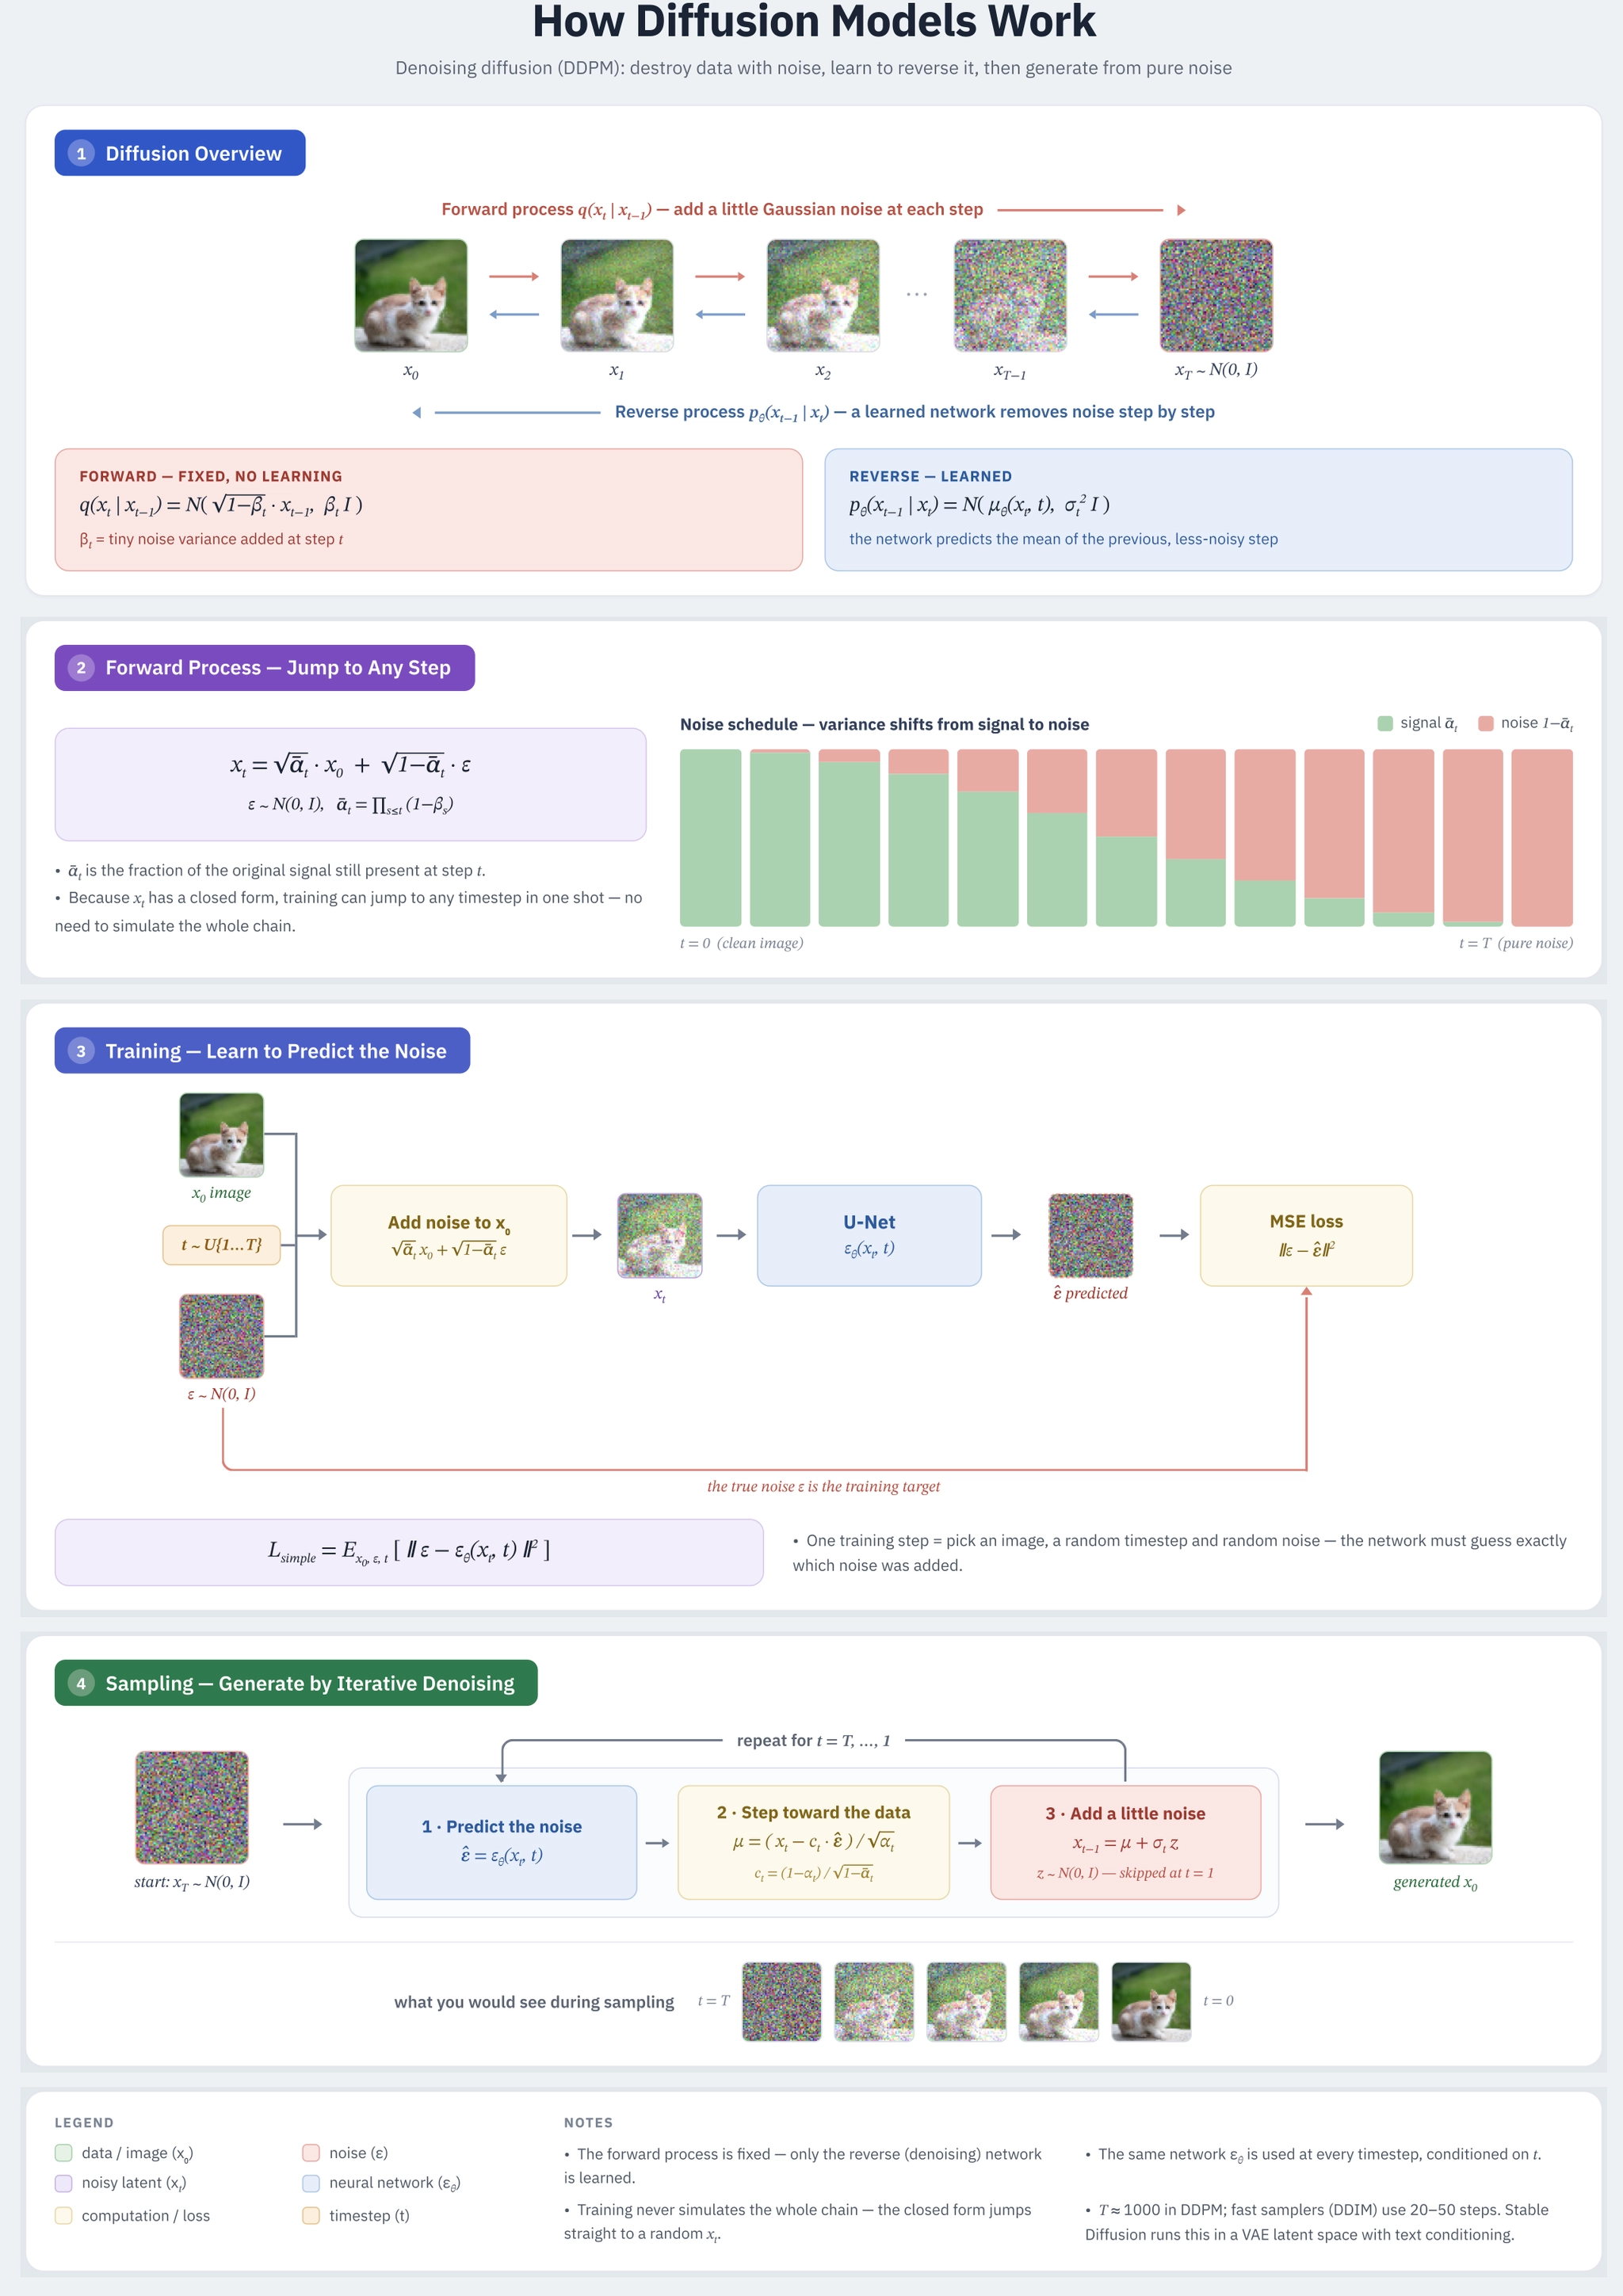


## 扩散模型训练（伪代码）
```text
for x0 in dataloader:                                  # clean data
    t   = torch.randint(0, T, (x0.shape[0],))          # random timestep
    eps = torch.randn_like(x0)                          # sample noise
    x_t = sqrt_ab[t] * x0 + sqrt_one_minus_ab[t] * eps  # forward process (closed form)
    loss = F.mse_loss(model(x_t, t), eps)               # predict the noise, plain MSE
```

## 扩散模型推理（伪代码）
```text
x = torch.randn(n, 1, 28, 28)                        # start from pure noise
for t in reversed(range(T)):                          # 1000 sequential steps
    eps = model(x, t)                                 # predict the noise
    x = (x - beta[t] / sqrt_one_minus_ab[t] * eps) / sqrt_a[t]  # remove a bit of noise
    if t > 0:
        x = x + sqrt_beta[t] * torch.randn_like(x)    # re-inject fresh noise (DDPM)
```


## Diffusion Policy

[Diffusion Policy](https://arxiv.org/abs/2303.04137) [Chi+, 2023] 把计算机视觉领域成功的**扩散模型用于生成动作**。它与上面的方法一样，从噪声中预测动作。

Diffusion Policy 不只预测一个时间步，而是一次预测多个时间步（例如 16、32）的动作序列。这能缓解误差累积（compounding error）。


In [ ]:
# Square ， Diffusion Policy（次帰比很大）
dp_square, cfg = build_model("diffusion_policy", SQUARE_DATA)
square_dp_loss = train(dp_square, make_loader(SQUARE_DATA, cfg), NUM_EPOCHS["diffusion_policy"], "diffusion/square")
np.random.seed(SEED); torch.manual_seed(SEED)
SUCCESS[("square", "diffusion_policy")] = evaluate(dp_square, square_env, cfg, N_ROLLOUTS, HORIZON["square"], "dp_square.mp4")


============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_eef_pos', 'robot0_gripper_qpos', 'robot0_eef_quat']
using obs modality: rgb with keys: ['robot0_eye_in_hand_image', 'agentview_image']
using obs modality: depth with keys: []
using obs modality: scan with keys: []
number of parameters: 6.914689e+07
SequenceDataset: loading dataset into memory...
100%|██████████████████████████████████████████████████| 200/200 [00:00<00:00, 933.91it/s]
SequenceDataset: computing action statistics...
100%|█████████████████████████████████████████████████| 199/199 [00:00<00:00, 4585.63it/s]
[diffusion/square] epoch    1/200  loss = 0.9846
[diffusion/square] epoch   25/200  loss = 0.0711
[diffusion/square] epoch   50/200  loss = 0.0626
[diffusion/square] epoch   75/200  loss = 0.0580
[diffusion/square] epoch  100/200  loss = 0.0549
[diffusion/square] epoch  125/200  loss = 0.0537
[diffusion/square] epoch  150/200  loss = 0.0498
[diffusi

In [ ]:
Video("dp_square.mp4", embed=True, width=320)

In [ ]:
# 参考: Lift 也 Diffusion Policy 训练（Lift 是两者的方策也解，的确认用）
dp_lift, cfg = build_model("diffusion_policy", LIFT_DATA)
lift_dp_loss = train(dp_lift, make_loader(LIFT_DATA, cfg), NUM_EPOCHS["diffusion_policy"], "diffusion/lift")
np.random.seed(SEED); torch.manual_seed(SEED)
SUCCESS[("lift", "diffusion_policy")] = evaluate(dp_lift, lift_env, cfg, N_ROLLOUTS, HORIZON["lift"], "dp_lift.mp4")


============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_eef_pos', 'robot0_gripper_qpos', 'robot0_eef_quat']
using obs modality: rgb with keys: ['robot0_eye_in_hand_image', 'agentview_image']
using obs modality: depth with keys: []
using obs modality: scan with keys: []
number of parameters: 6.914689e+07
SequenceDataset: loading dataset into memory...
100%|██████████████████████████████████████████████████| 200/200 [00:00<00:00, 961.70it/s]
SequenceDataset: computing action statistics...
100%|█████████████████████████████████████████████████| 199/199 [00:00<00:00, 4932.78it/s]
[diffusion/lift] epoch    1/200  loss = 0.9855
[diffusion/lift] epoch   25/200  loss = 0.0511
[diffusion/lift] epoch   50/200  loss = 0.0514
[diffusion/lift] epoch   75/200  loss = 0.0378
[diffusion/lift] epoch  100/200  loss = 0.0403
[diffusion/lift] epoch  125/200  loss = 0.0340
[diffusion/lift] epoch  150/200  loss = 0.0331
[diffusion/lift] epoch

## 成功率比较

像 Lift 这样短且解法唯一的任务，回归策略和 Diffusion Policy 都能解决。对于 Square 这类长且精细的任务，逐步预测的回归策略容易因误差累积而崩溃，而生成动作序列的 Diffusion Policy 通常更能坚持。下面的图展示这种差异。

成功率来自每个设置 20 次 rollout、1 个随机种子，没有误差棒。请把它作为趋势而非绝对数值来读（增加训练量后两者都可能提升）。


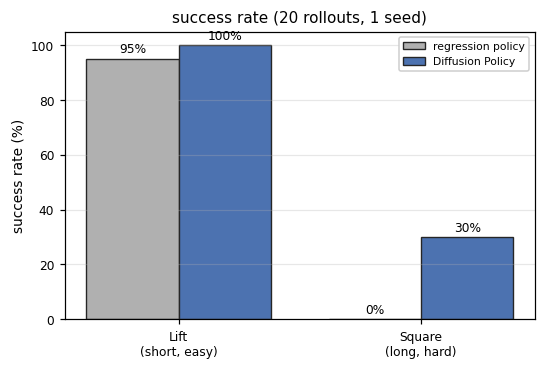

In [ ]:
tasks   = ["lift", "square"]
reg_vals = np.array([SUCCESS[(t, "bc")] for t in tasks]) * 100
dp_vals  = np.array([SUCCESS[(t, "diffusion_policy")] for t in tasks]) * 100

x, bw = np.arange(len(tasks)), 0.38
fig, ax = plt.subplots(figsize=(5.0, 3.4))
ax.bar(x - bw/2, reg_vals, bw, color=GRAY,   edgecolor="0.15", linewidth=0.9, label="regression policy")
ax.bar(x + bw/2, dp_vals,  bw, color=ACCENT, edgecolor="0.15", linewidth=0.9, label="Diffusion Policy")
for xi, v in zip(x - bw/2, reg_vals): ax.annotate(f"{v:.0f}%", (xi, v), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=8)
for xi, v in zip(x + bw/2, dp_vals):  ax.annotate(f"{v:.0f}%", (xi, v), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(["Lift\n(short, easy)", "Square\n(long, hard)"])
ax.set_ylabel("success rate (%)"); ax.set_ylim(0, 105)
ax.set_title(f"success rate ({N_ROLLOUTS} rollouts, 1 seed)")
ax.grid(True, axis="y", alpha=0.3); ax.legend(framealpha=0.95, loc="upper right")
fig.tight_layout(); plt.show()

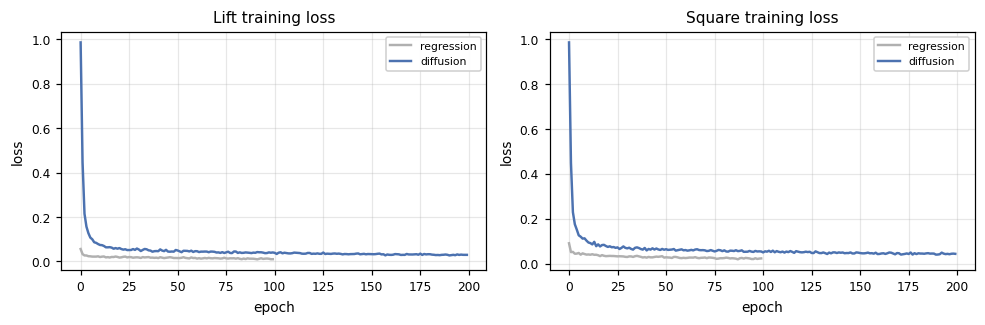

In [ ]:
# 训练曲线（次帰与拡散是損失的定義按物因此，形仅查看）
fig, axes = plt.subplots(1, 2, figsize=(9, 3.0))
axes[0].plot(lift_reg_loss, color=GRAY,   lw=1.6, label="regression"); axes[0].plot(lift_dp_loss, color=ACCENT, lw=1.6, label="diffusion")
axes[0].set_title("Lift training loss")
axes[1].plot(square_reg_loss, color=GRAY, lw=1.6, label="regression"); axes[1].plot(square_dp_loss, color=ACCENT, lw=1.6, label="diffusion")
axes[1].set_title("Square training loss")
for ax in axes:
    ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.grid(True, alpha=0.3); ax.legend(framealpha=0.95)
fig.tight_layout(); plt.show()

关于损失：回归使用动作的二次误差，扩散使用噪声预测的二次误差，定义不同，因此不能比较损失绝对值；应比较成功率。


## 总结

本 notebook 介绍了模仿学习，尤其是 BC 的一些近期主题。

- 用一个点表示动作的回归策略有两个问题：多峰数据会把多个正确答案平均掉；长轨迹中误差会累积。
- 用分布表示动作的方法可以缓解第一个问题；以序列输出动作（action chunking）的方法可以缓解第二个问题。
- 训练前了解数据集性质非常重要。本次查看了初始状态叠加、动作分布和三维轨迹。

**拓展实验**

- 增大 `NUM_EPOCHS`，或把 `N_DEMOS` 设为 `None` 使用全部示范，观察成功率变化；
- 尝试 `transport` / `tool_hang` 等更长任务，观察误差累积与序列生成的优势。

**参考链接**

- robomimic：https://robomimic.github.io/docs/index.html
- robosuite：https://robosuite.ai/
- Diffusion Policy (Chi et al., 2023)：https://diffusion-policy.cs.columbia.edu/
- ACT (Chao et al., 2023)：https://arxiv.org/abs/2304.13705
- ROS2 入门 1：https://www.docswell.com/s/tatsukamijo/K332P2-2025-07-16-234918
- ROS2 入门 2：https://skinny-chord-c58.notion.site/5-ROS-2-2-2-2049a7a1061380fc8928e500eafc57d0
